In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    mutual_info_score
)
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestClassifier  

import xgboost as xgb




In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hopesb/student-depression-dataset",
    output_dir="./student_depression_dataset")

print("Path to dataset files:", path)




Path to dataset files: ./student_depression_dataset


In [3]:
df= pd.read_csv(path+"/Student Depression Dataset.csv")
df.head()

,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


In [4]:
df.columns=df.columns.str.lower().str.replace(" ", "_")
for col in df.columns:
    if (df[col].dtype=="str"):
        df[col]= df[col].str.lower().str.replace(" ","_")



In [5]:
del df["id"]
del df["profession"]
del df["work_pressure"]
del df["job_satisfaction"]
del df["city"]

In [6]:
df=df.dropna().reset_index(drop=True)
categorical_columns=["gender","sleep_duration","dietary_habits","degree","have_you_ever_had_suicidal_thoughts_?","family_history_of_mental_illness"]
numerical_columns=["age","academic_pressure","cgpa","study_satisfaction","work/study_hours","financial_stress"]
df.head()

,gender,age,academic_pressure,cgpa,study_satisfaction,sleep_duration,dietary_habits,degree,have_you_ever_had_suicidal_thoughts_?,work/study_hours,financial_stress,family_history_of_mental_illness,depression
0,male,33.0,5.0,8.97,2.0,5-6_hours,healthy,b.pharm,yes,3.0,1.0,no,1
1,female,24.0,2.0,5.90,5.0,5-6_hours,moderate,bsc,no,3.0,2.0,yes,0
2,male,31.0,3.0,7.03,5.0,less_than_5_hours,healthy,ba,no,9.0,1.0,yes,0
3,female,28.0,3.0,5.59,2.0,7-8_hours,moderate,bca,yes,4.0,5.0,yes,1
4,female,25.0,4.0,8.13,3.0,5-6_hours,moderate,m.tech,yes,1.0,1.0,no,0


In [7]:
def score(series):
    return mutual_info_score(df["depression"],series)

mi_score=df[categorical_columns].apply(score)
mi_score.sort_values(ascending=False)

have_you_ever_had_suicidal_thoughts_?    0.154647
dietary_habits                           0.021851
degree                                   0.009770
sleep_duration                           0.004968
family_history_of_mental_illness         0.001435
gender                                   0.000002
dtype: float64

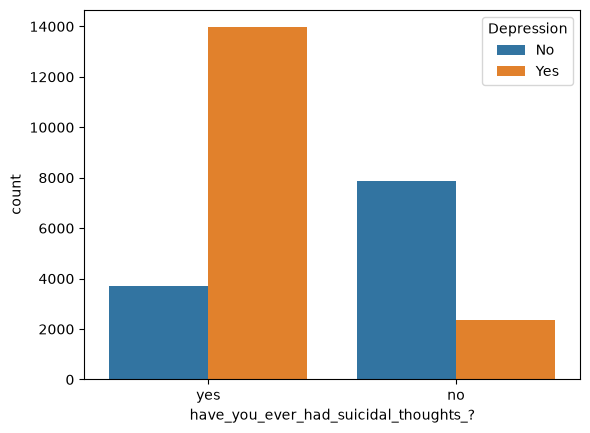

In [8]:
sns.countplot(data=df, x="have_you_ever_had_suicidal_thoughts_?", hue="depression")
plt.legend(title="Depression", labels=["No", "Yes"])
plt.show()

In [9]:
df[numerical_columns].corrwith(df.depression).abs().sort_values(ascending=False)

academic_pressure     0.474793
financial_stress      0.363591
age                   0.226511
work/study_hours      0.208627
study_satisfaction    0.168010
cgpa                  0.022268
dtype: float64

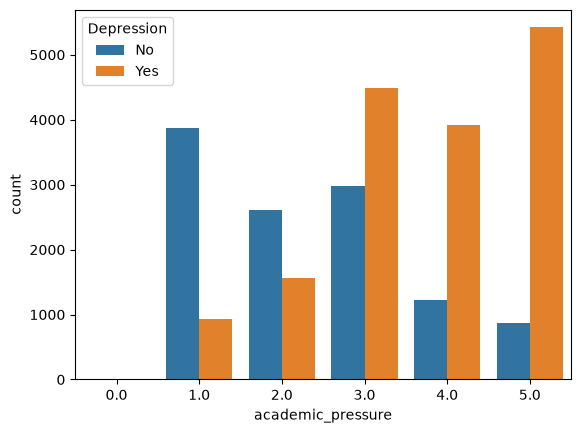

In [10]:
sns.countplot(data=df, x="academic_pressure", hue="depression" )
plt.legend(title="Depression", labels=["No", "Yes"])
plt.show()